1. Type d'apprentissage

Une banque veut savoir si un client va rembourser son prêt. Pour chacun des 1 000 clients, on connaît la réponse (bon ou mauvais risque) : il s'agit d'un problème d'**apprentissage supervisé**. La cible ne prend que deux valeurs : c'est une **classification binaire**.

Les deux erreurs possibles n'ont pas le même coût : accepter un mauvais risque fait perdre le capital prêté, alors que refuser un bon client fait seulement perdre les intérêts. Le projet est donc une classification **à coûts asymétriques**, et la question centrale est : **quel seuil de décision faut-il choisir ?**

In [44]:
# Importation des bibliothèques
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, cross_val_score, cross_val_predict,
                                     learning_curve, validation_curve, StratifiedKFold)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, classification_report

# Reproductibilité et style des graphiques
np.random.seed(42)
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110

# Dossier des figures (utilisées ensuite dans le rapport LaTeX)
def sauver(nom):
    """Enregistre la figure courante en PDF dans le dossier figures."""
    plt.savefig(f"figures/{nom}.pdf", bbox_inches="tight")

## 2. Le jeu de données

Le jeu de données est le **Statlog (German Credit Data)** de l'UCI Machine Learning Repository (n° 144) : https://archive.ics.uci.edu/dataset/144. Il contient 1 000 dossiers de clients, 20 variables et une cible. Les colonnes ont été renommées de façon explicite.

| Colonne | Signification |
|---|---|
| statut_compte | Statut du compte courant (A11 à A14) |
| duree_mois | Durée du crédit en mois |
| historique_credit | Historique de crédit (A30 à A34) |
| objet | Objet du crédit (A40 à A410) |
| montant | Montant du crédit (en marks allemands, DM) |
| epargne | Épargne et obligations (A61 à A65) |
| anciennete_emploi | Ancienneté dans l'emploi actuel (A71 à A75) |
| taux_mensualite | Mensualité en % du revenu disponible (1 à 4) |
| statut_perso_sexe | Statut personnel et sexe (A91 à A95) |
| autres_debiteurs | Autres débiteurs ou garants (A101 à A103) |
| anciennete_residence | Ancienneté de résidence (1 à 4) |
| bien | Bien le plus précieux possédé (A121 à A124) |
| age | Âge en années |
| autres_credits | Autres crédits en cours (A141 à A143) |
| logement | Type de logement (A151 à A153) |
| nb_credits | Nombre de crédits dans cette banque |
| emploi | Type d'emploi (A171 à A174) |
| nb_personnes_charge | Nombre de personnes à charge |
| telephone | Téléphone (A191, A192) |
| travailleur_etranger | Travailleur étranger (A201, A202) |
| **risque** | **Cible : 1 = bon risque, 2 = mauvais risque** |

Les valeurs du type `A11` sont des codes de catégories définis dans la documentation UCI.

### Lien entre le CSV et Google Drive

Le fichier `german_credit.csv` est stocké dans le dossier `risque_credit` de ton Google Drive, puis lu depuis Colab. Les deux cellules suivantes connectent le Drive, puis créent le fichier **une seule fois** s'il n'existe pas encore.

In [45]:
# Connexion à Google Drive et définition du chemin du fichier CSV
from google.colab import drive
drive.mount("/content/drive")

DOSSIER = "/content/drive/MyDrive/risque_credit_allemagne"
CHEMIN_CSV = f"{DOSSIER}/german_credit.csv"
print("Chemin du CSV :", CHEMIN_CSV)
# Les figures et les tableaux du rapport sont enregistrés directement dans le Drive
DOSSIER_FIG = f"{DOSSIER}/figures"
os.makedirs(DOSSIER_FIG, exist_ok=True)

def sauver(nom):
    """Enregistre la figure courante en PDF dans le dossier figures du Drive."""
    plt.savefig(f"{DOSSIER_FIG}/{nom}.pdf", bbox_inches="tight")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Chemin du CSV : /content/drive/MyDrive/risque_credit_allemagne/german_credit.csv


In [46]:
# Création du CSV sur le Drive (une seule fois : ignorée si le fichier existe déjà)
import subprocess, sys

if os.path.exists(CHEMIN_CSV):
    print("Le fichier existe déjà, rien à faire :", CHEMIN_CSV)
else:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ucimlrepo"], check=True)
    from ucimlrepo import fetch_ucirepo

    brut = fetch_ucirepo(id=144)                       # Statlog (German Credit Data)
    donnees = brut.data.features.copy()
    donnees["risque"] = brut.data.targets.iloc[:, 0]   # 1 = bon risque, 2 = mauvais risque

    # Noms de colonnes explicites, dans l'ordre des attributs 1 à 20 de la documentation UCI
    donnees.columns = [
        "statut_compte", "duree_mois", "historique_credit", "objet", "montant",
        "epargne", "anciennete_emploi", "taux_mensualite", "statut_perso_sexe",
        "autres_debiteurs", "anciennete_residence", "bien", "age", "autres_credits",
        "logement", "nb_credits", "emploi", "nb_personnes_charge", "telephone",
        "travailleur_etranger", "risque",
    ]
    os.makedirs(DOSSIER, exist_ok=True)
    donnees.to_csv(CHEMIN_CSV, index=False)
    print("Fichier créé :", CHEMIN_CSV, "|", donnees.shape)

Le fichier existe déjà, rien à faire : /content/drive/MyDrive/risque_credit_allemagne/german_credit.csv


In [47]:
# Chargement du jeu de données depuis le CSV
SOURCE = "drive"   # "drive" (Google Drive)
URL_CSV = "/content/drive/MyDrive/risque_credit_allemagne/german_credit.csv"

if SOURCE == "drive":
    df = pd.read_csv(CHEMIN_CSV)
else:
    df = pd.read_csv(URL_CSV)

print("Dimensions :", df.shape)
df.head()

Dimensions : (1000, 21)


,statut_compte,duree_mois,historique_credit,objet,montant,epargne,anciennete_emploi,taux_mensualite,statut_perso_sexe,autres_debiteurs,...,bien,age,autres_credits,logement,nb_credits,emploi,nb_personnes_charge,telephone,travailleur_etranger,risque
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


## 3. Première exploration

Avant de modéliser, on regarde la structure du jeu de données : types, valeurs manquantes, doublons et statistiques descriptives.

In [48]:
# Types des colonnes, valeurs manquantes et doublons
df.info()
print("\nValeurs manquantes (total) :", df.isna().sum().sum())
print("Lignes dupliquées          :", df.duplicated().sum())
print("\nNombre de modalités des variables catégorielles :")
print(df.select_dtypes(exclude="number").nunique().to_string())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   statut_compte         1000 non-null   object
 1   duree_mois            1000 non-null   int64 
 2   historique_credit     1000 non-null   object
 3   objet                 1000 non-null   object
 4   montant               1000 non-null   int64 
 5   epargne               1000 non-null   object
 6   anciennete_emploi     1000 non-null   object
 7   taux_mensualite       1000 non-null   int64 
 8   statut_perso_sexe     1000 non-null   object
 9   autres_debiteurs      1000 non-null   object
 10  anciennete_residence  1000 non-null   int64 
 11  bien                  1000 non-null   object
 12  age                   1000 non-null   int64 
 13  autres_credits        1000 non-null   object
 14  logement              1000 non-null   object
 15  nb_credits            1000 non-null   i

In [49]:
# Statistiques descriptives des variables numériques
df.drop(columns="risque").describe().round(1)

,duree_mois,montant,taux_mensualite,anciennete_residence,age,nb_credits,nb_personnes_charge
count,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0
mean,20.9,3271.3,3.0,2.8,35.5,1.4,1.2
std,12.1,2822.7,1.1,1.1,11.4,0.6,0.4
min,4.0,250.0,1.0,1.0,19.0,1.0,1.0
25%,12.0,1365.5,2.0,2.0,27.0,1.0,1.0
50%,18.0,2319.5,3.0,3.0,33.0,1.0,1.0
75%,24.0,3972.2,4.0,4.0,42.0,2.0,1.0
max,72.0,18424.0,4.0,4.0,75.0,4.0,2.0


**Lecture.** Le jeu contient 1 000 lignes et 21 colonnes : 13 variables catégorielles (codes du type `A11`) et 8 colonnes numériques (7 variables et la cible). Il n'y a **aucune valeur manquante et aucun doublon** : l'étape de nettoyage ne supprimera rien, mais on la montre quand même dans la préparation.

Les variables numériques ont des échelles très différentes : le montant va de 250 à 18 424 DM, la durée de 4 à 72 mois, et les mensualités de 1 à 4. Le montant moyen (3 271 DM) est nettement supérieur à sa médiane (2 320 DM), ce qui indique une distribution asymétrique, avec quelques très gros crédits. Il faudra **standardiser** ces variables.

*texte en italique*## 4. Visualisation

### 4.1 Répartition de la cible

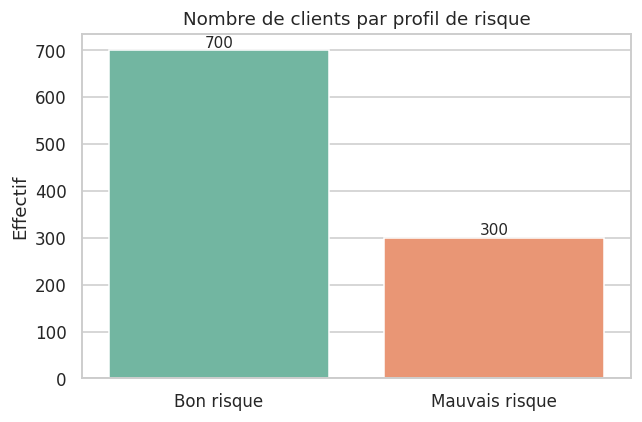

profil
Bon risque        0.7
Mauvais risque    0.3
Name: proportion, dtype: float64


In [50]:
# Étiquette lisible de la cible, pour les graphiques (1 = bon risque, 2 = mauvais risque)
df["profil"] = df["risque"].map({1: "Bon risque", 2: "Mauvais risque"})
ordre_profil = ["Bon risque", "Mauvais risque"]

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x="profil", order=ordre_profil, hue="profil", legend=False, ax=ax)
for patch in ax.patches:
    ax.annotate(f"{int(patch.get_height())}",
                (patch.get_x() + patch.get_width() / 2, patch.get_height()),
                ha="center", va="bottom", fontsize=10)
ax.set_title("Nombre de clients par profil de risque")
ax.set_xlabel("")
ax.set_ylabel("Effectif")
plt.tight_layout()
sauver("repartition_cible")
plt.show()
print(df["profil"].value_counts(normalize=True).round(3))

**Lecture.** Les classes sont déséquilibrées : 700 bons risques (70 %) pour 300 mauvais risques (30 %). Deux conséquences : le découpage entraînement/test devra être **stratifié** pour garder cette proportion, et l'**exactitude** serait trompeuse, car accepter tout le monde donnerait déjà 70 % de bonnes décisions. On évaluera donc les modèles avec l'**AUC**, puis avec les **coûts**.

### 4.2 Distributions des variables numériques

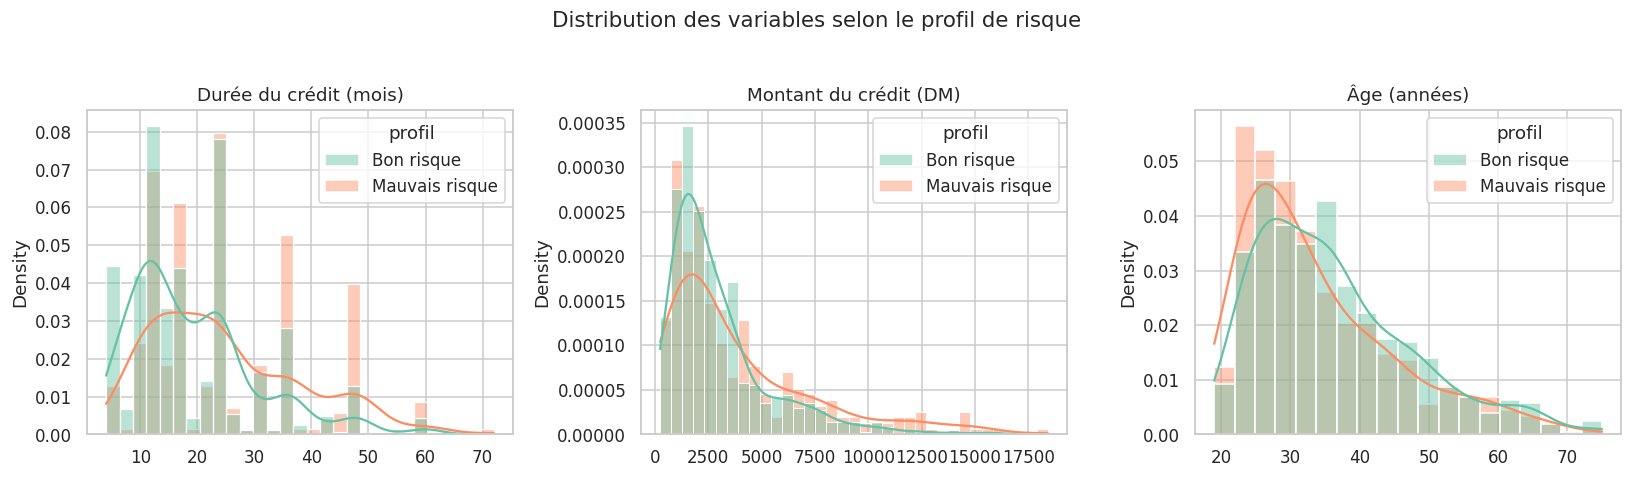

In [51]:
# Histogrammes superposés des variables numériques continues, par profil de risque
variables_hist = ["duree_mois", "montant", "age"]
titres_hist = ["Durée du crédit (mois)", "Montant du crédit (DM)", "Âge (années)"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, var, titre in zip(axes, variables_hist, titres_hist):
    sns.histplot(data=df, x=var, hue="profil", hue_order=ordre_profil, kde=True,
                 stat="density", common_norm=False, alpha=0.45, ax=ax)
    ax.set_title(titre)
    ax.set_xlabel("")
plt.suptitle("Distribution des variables selon le profil de risque", fontsize=14, y=1.03)
plt.tight_layout()
sauver("distributions")
plt.show()

**Lecture.** Les mauvais risques ont en moyenne des crédits plus longs (24,9 mois contre 19,2) et plus élevés (3 938 DM contre 2 986), et ils sont un peu plus jeunes (34,0 ans contre 36,2). Mais les distributions se **chevauchent largement** : aucune variable seule ne sépare nettement les deux profils. Le montant a une longue queue vers la droite.

### 4.3 Relation entre deux variables

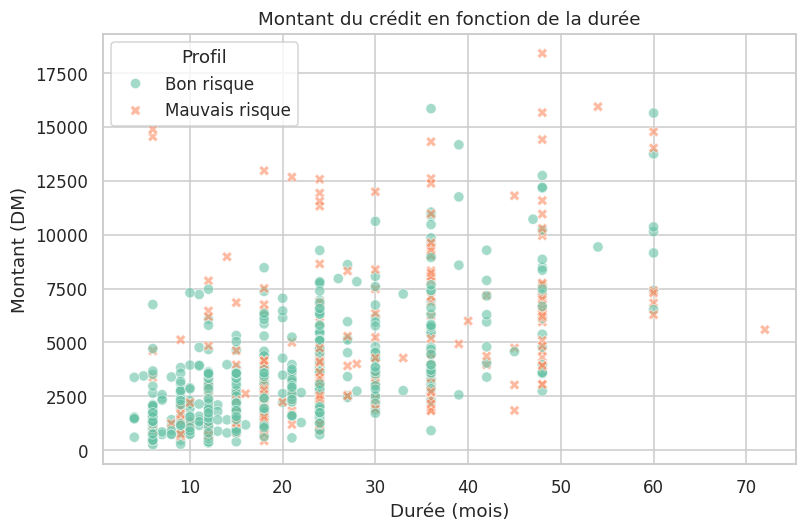

In [52]:
# Nuage de points : montant du crédit en fonction de la durée
fig, ax = plt.subplots(figsize=(7.5, 5))
sns.scatterplot(data=df, x="duree_mois", y="montant", hue="profil", hue_order=ordre_profil,
                style="profil", style_order=ordre_profil, s=45, alpha=0.6, ax=ax)
ax.set_title("Montant du crédit en fonction de la durée")
ax.set_xlabel("Durée (mois)")
ax.set_ylabel("Montant (DM)")
ax.legend(title="Profil")
plt.tight_layout()
sauver("nuage_montant_duree")
plt.show()

**Lecture.** Les crédits longs sont aussi les plus élevés (corrélation de 0,62 entre durée et montant). Les mauvais risques sont un peu plus fréquents dans la zone des crédits longs et élevés, mais les deux classes restent très mélangées : un modèle devra combiner plusieurs variables.

### 4.4 Boîtes à moustaches et corrélations

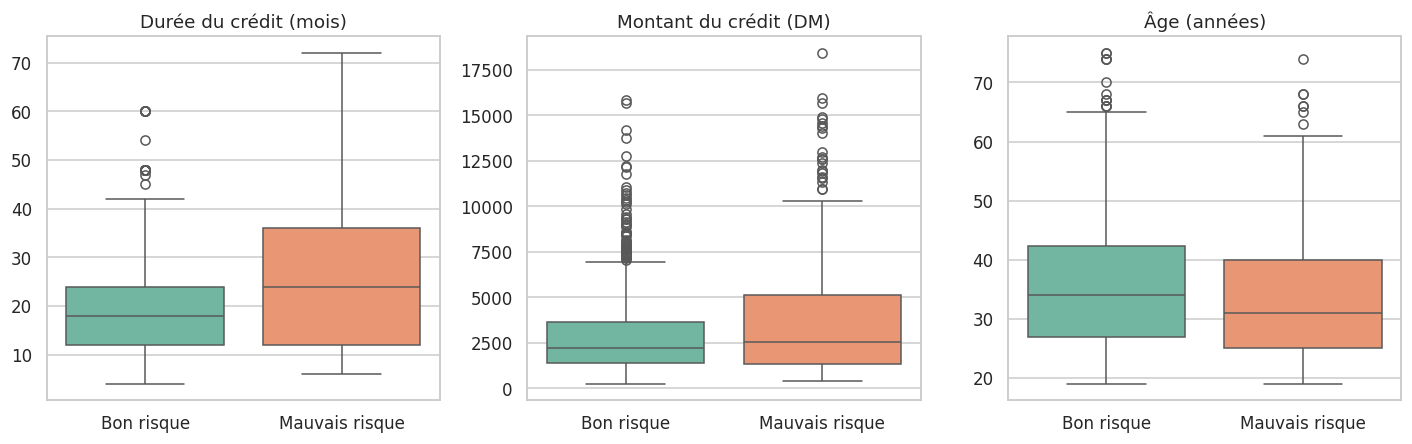

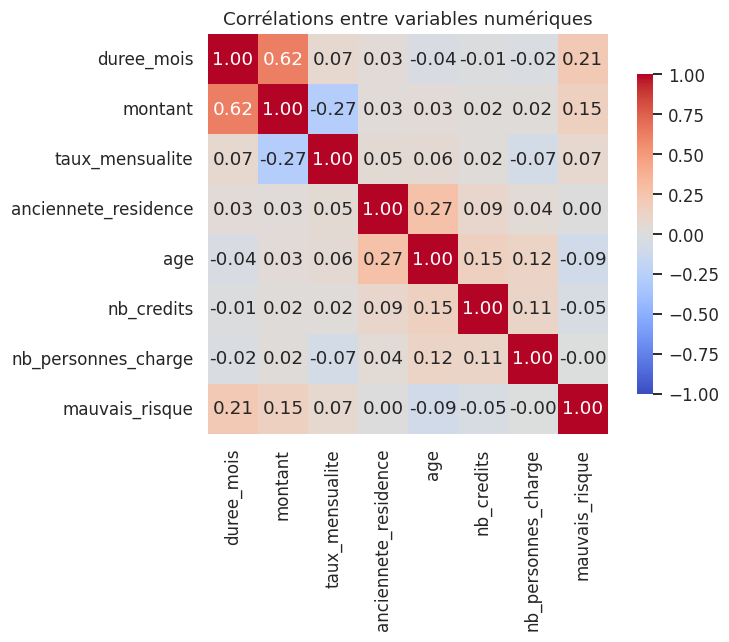

In [53]:
# Boîtes à moustaches par profil de risque
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, var, titre in zip(axes, variables_hist, titres_hist):
    sns.boxplot(data=df, x="profil", y=var, order=ordre_profil, hue="profil", legend=False, ax=ax)
    ax.set_title(titre)
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.tight_layout()
sauver("boites_moustaches")
plt.show()

# Matrice de corrélation des variables numériques, avec la cible (1 = mauvais risque)
num = (df.select_dtypes(include="number").drop(columns="risque")
         .assign(mauvais_risque=(df["risque"] == 2).astype(int)))
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Corrélations entre variables numériques")
plt.tight_layout()
sauver("correlations")
plt.show()

**Lecture.** Les boîtes confirment que les médianes de durée et de montant sont plus élevées chez les mauvais risques, avec de nombreuses valeurs extrêmes pour le montant. Les corrélations avec la cible sont **faibles** : 0,21 pour la durée, 0,15 pour le montant, -0,09 pour l'âge, et presque 0 pour les autres. Aucune variable numérique ne suffit seule, et ces corrélations mesurent seulement des liens linéaires : elles n'indiquent **aucune causalité**.

### 4.5 Variables catégorielles

Les variables catégorielles sont souvent les plus informatives dans ce jeu de données. D'après la documentation UCI, le statut du compte courant a quatre valeurs : A11 (solde négatif), A12 (entre 0 et 200 DM), A13 (200 DM ou plus) et A14 (pas de compte courant). L'historique de crédit va de A30 (aucun crédit pris ou tous remboursés) à A34 (compte critique ou autres crédits existants).

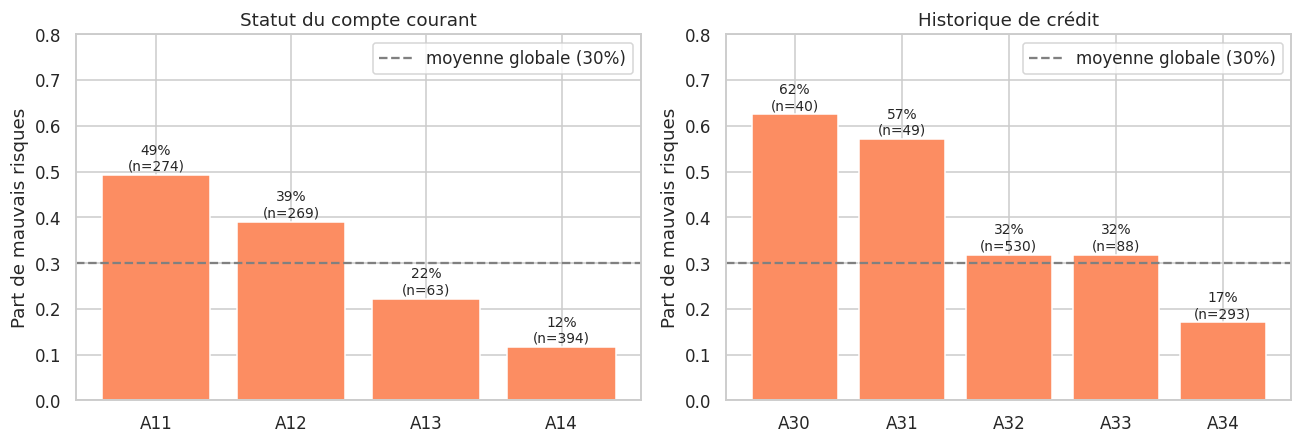

In [54]:
# Part de mauvais risques selon deux variables catégorielles
taux_global = (df["risque"] == 2).mean()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, var, titre in zip(axes, ["statut_compte", "historique_credit"],
                          ["Statut du compte courant", "Historique de crédit"]):
    part = (df.assign(mauvais=(df["risque"] == 2)).groupby(var)["mauvais"].mean().sort_index())
    effectifs = df[var].value_counts().reindex(part.index)
    ax.bar(part.index, part.values, color=sns.color_palette("Set2")[1])
    ax.axhline(taux_global, color="grey", linestyle="--", label=f"moyenne globale ({taux_global:.0%})")
    for i, (val, n) in enumerate(zip(part.values, effectifs.values)):
        ax.text(i, val + 0.01, f"{val:.0%}\n(n={n})", ha="center", fontsize=9)
    ax.set_ylim(0, 0.8)
    ax.set_title(titre)
    ax.set_ylabel("Part de mauvais risques")
    ax.legend(loc="upper right")
plt.tight_layout()
sauver("part_mauvais_risques")
plt.show()

**Lecture.** Le **statut du compte courant** est très discriminant : 49 % de mauvais risques pour A11 (n = 274) et 39 % pour A12 (n = 269), contre 22 % pour A13 (n = 63) et seulement 12 % pour A14 (n = 394), pour une moyenne de 30 %.

L'**historique de crédit** est moins intuitif : A30 et A31 ont les taux les plus élevés (62 % et 57 %), alors que A34 (compte critique) a le plus bas (17 %). Ces deux premières catégories ont de petits effectifs (n = 40 et 49), et la relation n'a probablement pas d'explication causale simple : le modèle apprendra des **associations statistiques**, qu'il ne faut pas interpréter comme des causes.

## 5. Préparation des données

La préparation suit quatre étapes :

1. **Nettoyage** : suppression des lignes incomplètes ou dupliquées (aucune ici, mais on le vérifie).
2. **Séparation** des variables d'entrée **X** et de la cible **y** (0 = bon risque, 1 = mauvais risque, pour que « mauvais risque » soit la classe positive).
3. **Découpage** en 70 % d'entraînement et 30 % de test. Il est **stratifié** : la proportion de 30 % de mauvais risques est conservée dans les deux parties.
4. **Prétraitement** dans un `ColumnTransformer` : standardisation des variables numériques (moyenne 0, écart-type 1) et encodage *one-hot* des variables catégorielles. Les codes comme `A11` n'ont pas d'ordre numérique, donc on les transforme en colonnes 0/1.

Ce prétraitement sera placé **dans un pipeline** avec chaque modèle : il est ainsi ajusté sur les données d'entraînement uniquement, ce qui évite toute **fuite d'information** depuis le jeu de test.

In [55]:
# 1) Suppression des lignes incomplètes ou dupliquées
df_propre = df.dropna().drop_duplicates().reset_index(drop=True)
print("Observations avant / après nettoyage :", len(df), "/", len(df_propre))

# 2) Séparation entrées / cible (0 = bon risque, 1 = mauvais risque)
y = (df_propre["risque"] == 2).astype(int)
X = df_propre.drop(columns=["risque", "profil"])

# 3) Découpage stratifié : 70 % entraînement, 30 % test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)
print("Entraînement :", X_train.shape[0], "| Test :", X_test.shape[0])
print("Part de mauvais risques : entraînement", round(y_train.mean(), 3),
      "| test", round(y_test.mean(), 3))

# 4) Prétraitement : standardisation des numériques, encodage des catégorielles
variables_num = X.select_dtypes(include="number").columns.tolist()
variables_cat = X.select_dtypes(exclude="number").columns.tolist()
print("Variables numériques :", len(variables_num), "| catégorielles :", len(variables_cat))

preprocesseur = ColumnTransformer([
    ("num", StandardScaler(), variables_num),
    ("cat", OneHotEncoder(handle_unknown="ignore"), variables_cat),
])

Observations avant / après nettoyage : 1000 / 1000
Entraînement : 700 | Test : 300
Part de mauvais risques : entraînement 0.3 | test 0.3
Variables numériques : 7 | catégorielles : 13


**Lecture.** Aucune ligne n'a été supprimée (1 000 avant et après). Le jeu d'entraînement compte 700 clients et le jeu de test 300, avec la même part de mauvais risques (30 %) grâce à la stratification. Le jeu de test est mis de côté : il ne servira qu'**une seule fois**, à l'évaluation finale. Les variables se répartissent en 7 numériques et 13 catégorielles.

## 6. Comparaison de modèles

### 6.1 Les modèles testés

On compare cinq modèles, tous précédés du même prétraitement :

- **Référence (hasard)** : ignore les variables d'entrée, et donne un AUC de 0,5. Un modèle n'a d'intérêt que s'il fait mieux.
- **Régression logistique** : modèle linéaire simple, qui estime directement une probabilité.
- **K plus proches voisins (k = 5)** : décide d'après les 5 clients les plus ressemblants.
- **Arbre de décision** (profondeur maximale 5) : suite de questions oui/non.
- **Forêt aléatoire** (300 arbres) : moyenne de nombreux arbres, plus stable qu'un arbre seul.

### 6.2 Validation croisée

Chaque modèle est évalué par **validation croisée stratifiée à 5 plis** sur l'entraînement : les données sont découpées en 5 parties, on entraîne sur 4 et on évalue sur la 5e, 5 fois de suite. La métrique est l'**AUC** (aire sous la courbe ROC) : c'est la probabilité qu'un mauvais risque tiré au hasard reçoive un score plus élevé qu'un bon client tiré au hasard. Elle vaut 0,5 pour le hasard et 1 pour un classement parfait. Elle ne dépend pas du seuil de décision, ce qui convient aux classes déséquilibrées.

In [56]:
# Modèles candidats, chacun précédé du même prétraitement
modeles = {
    "Référence (hasard)": DummyClassifier(strategy="prior"),
    "Régression logistique": LogisticRegression(max_iter=1000),
    "K plus proches voisins (k=5)": KNeighborsClassifier(n_neighbors=5),
    "Arbre de décision": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Forêt aléatoire": RandomForestClassifier(n_estimators=300, random_state=42),
}

pipelines = {nom: Pipeline([("prep", preprocesseur), ("modele", m)])
             for nom, m in modeles.items()}

validation = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
resultats = []
for nom, pipe in pipelines.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=validation, scoring="roc_auc")
    resultats.append({"Modèle": nom, "AUC moyen": scores.mean(), "Écart-type": scores.std()})

tableau = pd.DataFrame(resultats).sort_values("AUC moyen", ascending=False)
tableau.round(3)

,Modèle,AUC moyen,Écart-type
4,Forêt aléatoire,0.785,0.046
1,Régression logistique,0.764,0.024
2,K plus proches voisins (k=5),0.695,0.043
3,Arbre de décision,0.668,0.050
0,Référence (hasard),0.500,0.000


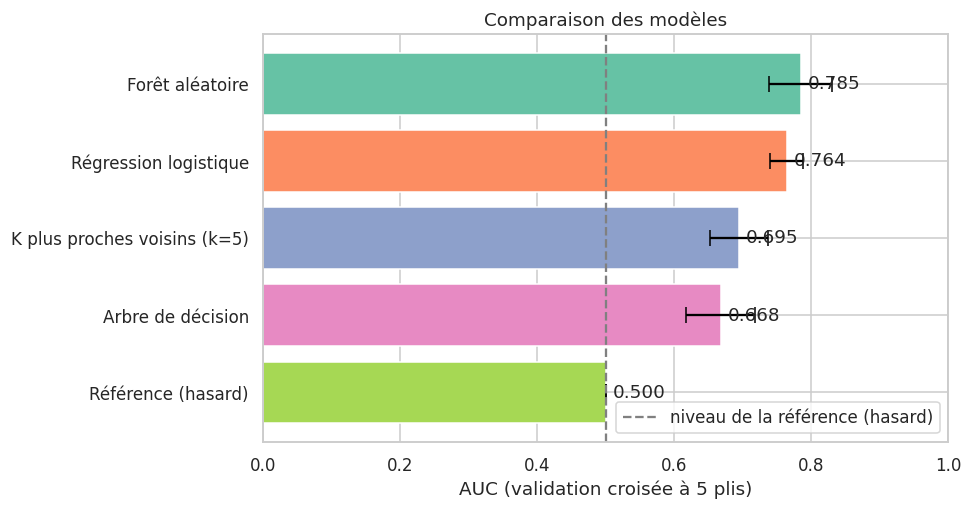

In [57]:
# Graphique : AUC moyen en validation croisée, avec barres d'erreur
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(tableau["Modèle"], tableau["AUC moyen"], xerr=tableau["Écart-type"],
        capsize=5, color=sns.color_palette("Set2", len(tableau)))
ax.set_xlim(0, 1.0)
ax.invert_yaxis()
ax.axvline(0.5, color="grey", linestyle="--", label="niveau de la référence (hasard)")
for i, val in enumerate(tableau["AUC moyen"]):
    ax.text(val + 0.01, i, f"{val:.3f}", va="center")
ax.set_xlabel("AUC (validation croisée à 5 plis)")
ax.set_title("Comparaison des modèles")
ax.legend(loc="lower right")
plt.tight_layout()
sauver("comparaison_modeles")
plt.show()

**Lecture.** Tous les modèles font mieux que la référence (AUC = 0,5). Le classement est : forêt aléatoire (0,785), régression logistique (0,764), K plus proches voisins (0,695), arbre de décision (0,668). Les écarts-types (0,046 pour la forêt, 0,024 pour la logistique) montrent que la forêt et la régression logistique sont **proches** : leur différence est inférieure à la variabilité entre plis. Le modèle retenu sera pourtant choisi par une règle fixée à l'avance : **le meilleur AUC en validation croisée**, sans regarder le jeu de test.

### 6.3 Effet de la profondeur de l'arbre

Un arbre trop profond mémorise les données d'entraînement (**surapprentissage**), un arbre trop simple ne capte pas la structure (**sous-apprentissage**). On fait varier la profondeur maximale et on compare l'AUC sur l'entraînement et en validation.

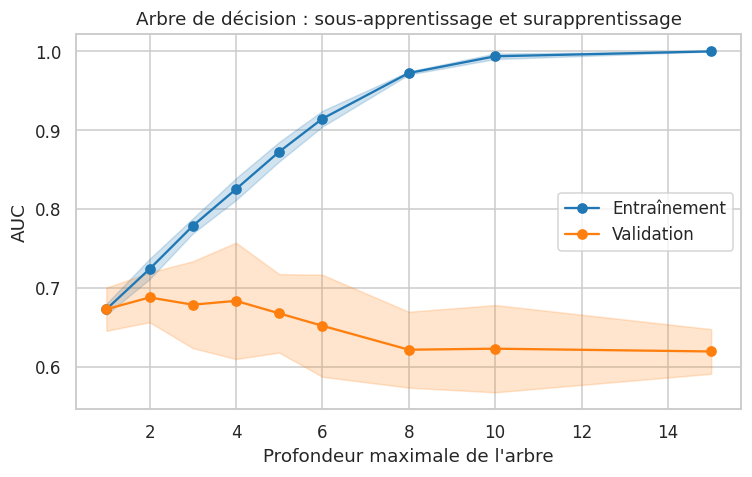

In [58]:
# Effet de la profondeur de l'arbre sur l'AUC (entraînement et validation)
profondeurs = [1, 2, 3, 4, 5, 6, 8, 10, 15]
arbre_pipe = Pipeline([("prep", preprocesseur),
                       ("modele", DecisionTreeClassifier(random_state=42))])
sc_train, sc_val = validation_curve(arbre_pipe, X_train, y_train,
                                    param_name="modele__max_depth", param_range=profondeurs,
                                    cv=validation, scoring="roc_auc")

fig, ax = plt.subplots(figsize=(7, 4.5))
for scores, label, couleur in [(sc_train, "Entraînement", "tab:blue"),
                               (sc_val, "Validation", "tab:orange")]:
    m, e = scores.mean(axis=1), scores.std(axis=1)
    ax.plot(profondeurs, m, "o-", color=couleur, label=label)
    ax.fill_between(profondeurs, m - e, m + e, alpha=0.2, color=couleur)
ax.set_xlabel("Profondeur maximale de l'arbre")
ax.set_ylabel("AUC")
ax.set_title("Arbre de décision : sous-apprentissage et surapprentissage")
ax.legend(loc="center right")
plt.tight_layout()
sauver("profondeur_arbre")
plt.show()

**Lecture.** L'AUC d'entraînement monte de 0,67 à 1,00 quand la profondeur augmente : l'arbre finit par **mémoriser** les 700 clients. L'AUC de validation fait l'inverse : elle est maximale pour une profondeur de 2 (environ 0,69), puis **diminue** jusqu'à environ 0,62 pour une profondeur de 15. C'est le signe classique du **surapprentissage**. Avec une profondeur de 5 (valeur utilisée dans la comparaison), l'AUC de validation est d'environ 0,67 : un arbre plus simple ferait un peu mieux, mais il resterait loin de la forêt aléatoire.

## 7. Évaluation finale sur le jeu de test

Jusqu'ici, les modèles ont été comparés par validation croisée sur l'entraînement. On sélectionne maintenant le meilleur selon une règle fixée à l'avance : **l'AUC moyen en validation croisée**. On entraîne ensuite tous les modèles sur l'ensemble de l'entraînement, et on les évalue **une seule fois** sur le jeu de test, que personne n'a encore vu.

### 7.1 AUC sur le test et courbes ROC

Un modèle donne pour chaque client une **probabilité d'être un mauvais risque**. La courbe ROC montre, pour chaque seuil de décision possible, le compromis entre les mauvais risques détectés (axe vertical) et les bons clients refusés à tort (axe horizontal). Plus la courbe s'éloigne de la diagonale (le hasard), meilleur est le modèle.

Meilleur modèle en validation croisée : Forêt aléatoire
                      Modèle  AUC test
       Régression logistique     0.801
             Forêt aléatoire     0.785
K plus proches voisins (k=5)     0.752
           Arbre de décision     0.647
          Référence (hasard)     0.500


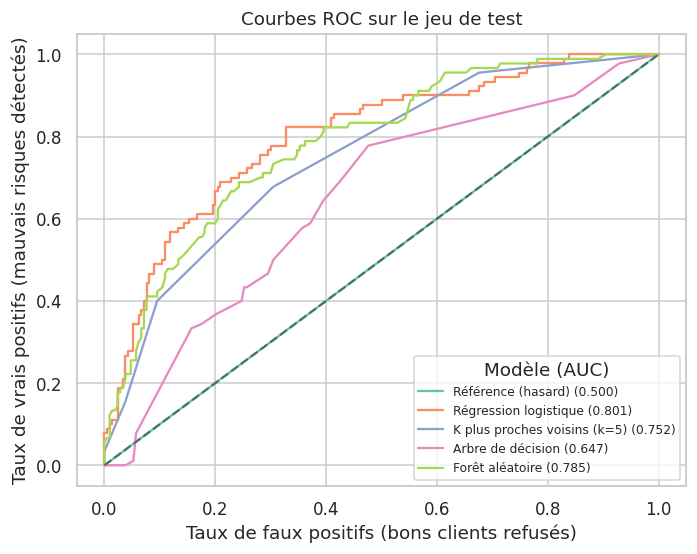


Rapport de classification : Forêt aléatoire, seuil 0,5
                precision    recall  f1-score   support

    Bon risque       0.77      0.93      0.84       210
Mauvais risque       0.69      0.37      0.48        90

      accuracy                           0.76       300
     macro avg       0.73      0.65      0.66       300
  weighted avg       0.75      0.76      0.73       300



In [59]:
# Sélection du meilleur modèle selon la validation croisée (jamais selon le test)
meilleur_nom = tableau.iloc[0]["Modèle"]
meilleur_pipe = pipelines[meilleur_nom]
print("Meilleur modèle en validation croisée :", meilleur_nom)

# Entraînement de tous les modèles sur l'ensemble d'entraînement, probabilités sur le test
probas_test = {}
for nom, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    probas_test[nom] = pipe.predict_proba(X_test)[:, 1]   # probabilité d'être un mauvais risque

df_test = pd.DataFrame(
    [(nom, roc_auc_score(y_test, p)) for nom, p in probas_test.items()],
    columns=["Modèle", "AUC test"]).sort_values("AUC test", ascending=False)
print(df_test.round(3).to_string(index=False))

# Courbes ROC
plt.figure(figsize=(6.5, 5.2))
for nom, p in probas_test.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f"{nom} ({roc_auc_score(y_test, p):.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.4)
plt.xlabel("Taux de faux positifs (bons clients refusés)")
plt.ylabel("Taux de vrais positifs (mauvais risques détectés)")
plt.title("Courbes ROC sur le jeu de test")
plt.legend(title="Modèle (AUC)", fontsize=8)
plt.tight_layout()
sauver("courbes_roc")
plt.show()

# Rapport de classification au seuil par défaut de 0,5
p_test = probas_test[meilleur_nom]
y_pred_05 = (p_test >= 0.5).astype(int)
print(f"\nRapport de classification : {meilleur_nom}, seuil 0,5")
print(classification_report(y_test, y_pred_05, target_names=["Bon risque", "Mauvais risque"]))

**Lecture.** Le modèle retenu par la validation croisée est la **forêt aléatoire**. Sur le test, les AUC sont : régression logistique 0,801, forêt aléatoire 0,785, K voisins 0,752, arbre de décision 0,647 et référence 0,5. Le classement entre les deux meilleurs s'inverse par rapport à la validation croisée, mais l'écart (0,016) est très inférieur à la variabilité observée (écart-type de 0,046 pour la forêt) : avec 300 clients de test, on ne peut pas conclure que l'un est meilleur que l'autre. On **garde la règle fixée à l'avance** (la forêt), pour ne pas choisir le modèle en regardant le test, ce qui fausserait l'évaluation. On reviendra sur ce point dans la partie coûts.

Au seuil par défaut de 0,5, la forêt a une exactitude de 0,76, mais cette valeur cache un déséquilibre : le rappel est de 0,93 pour les bons risques mais de **0,37 seulement pour les mauvais risques**. Le modèle laisse donc passer la majorité des mauvais clients.

### 7.2 Matrice de confusion (seuil 0,5)

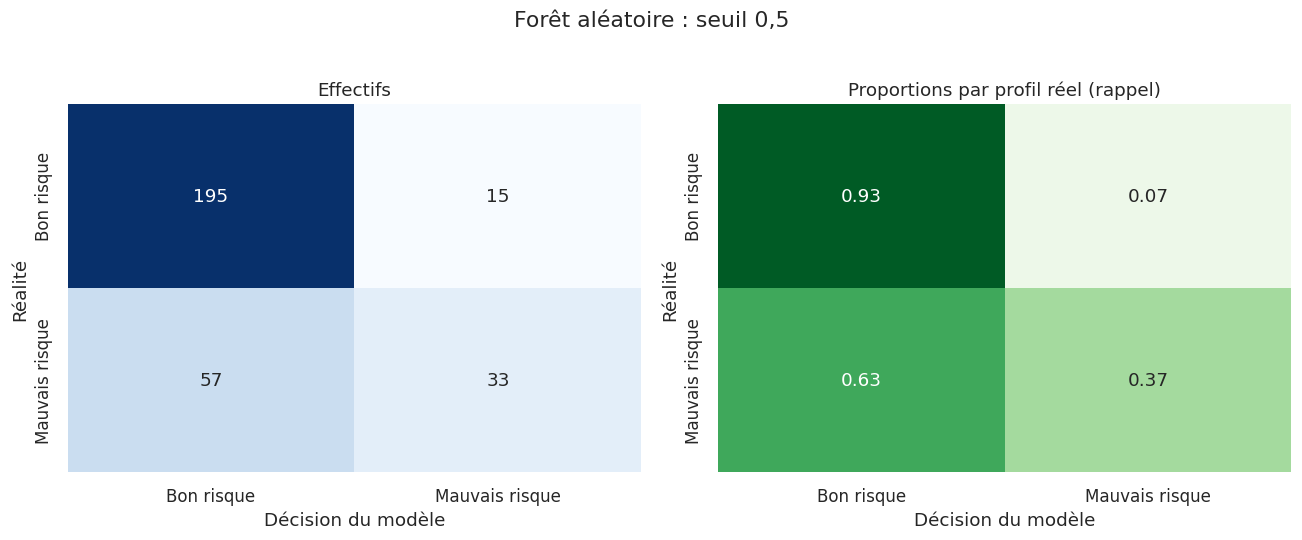

In [60]:
# Matrice de confusion au seuil 0,5 : valeurs absolues et proportions par ligne
etiquettes = ["Bon risque", "Mauvais risque"]
cm = confusion_matrix(y_test, y_pred_05, labels=[0, 1])
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=etiquettes,
            yticklabels=etiquettes, cbar=False, ax=axes[0])
axes[0].set_title("Effectifs")
axes[0].set_xlabel("Décision du modèle")
axes[0].set_ylabel("Réalité")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Greens", xticklabels=etiquettes,
            yticklabels=etiquettes, vmin=0, vmax=1, cbar=False, ax=axes[1])
axes[1].set_title("Proportions par profil réel (rappel)")
axes[1].set_xlabel("Décision du modèle")
axes[1].set_ylabel("Réalité")
plt.suptitle(f"{meilleur_nom} : seuil 0,5", y=1.02)
plt.tight_layout()
sauver("matrice_confusion_05")
plt.show()

**Lecture.** Sur les 300 clients du test (210 bons, 90 mauvais), le modèle accepte à tort **57 mauvais risques** (faux négatifs) et refuse **15 bons clients** (faux positifs). Il détecte seulement 33 mauvais risques sur 90, soit 37 %. L'exactitude de 76 % est trompeuse : accepter tout le monde donnerait déjà 70 %. Au seuil de 0,5, les deux erreurs sont traitées comme si elles coûtaient autant, alors que laisser passer un mauvais risque est beaucoup plus grave pour la banque : c'est ce qui justifiera la partie sur les coûts.

### 7.3 Courbe d'apprentissage

La courbe d'apprentissage montre l'AUC du modèle en fonction du nombre d'observations d'entraînement. Elle indique si le modèle manque de données ou s'il surapprend.

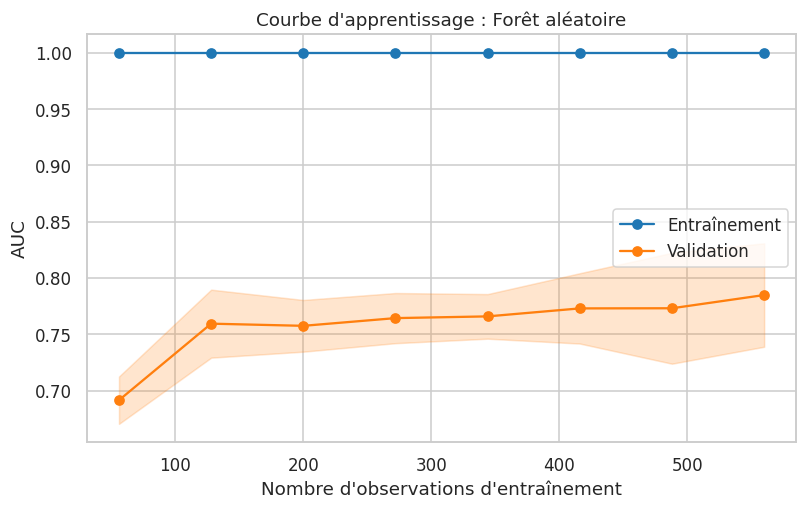

In [61]:
# Courbe d'apprentissage du meilleur modèle
tailles, scores_train, scores_val = learning_curve(
    meilleur_pipe, X_train, y_train,
    train_sizes=np.linspace(0.1, 1.0, 8), cv=validation, scoring="roc_auc", n_jobs=-1
)

fig, ax = plt.subplots(figsize=(7.5, 4.8))
for scores, label, couleur in [(scores_train, "Entraînement", "tab:blue"),
                               (scores_val, "Validation", "tab:orange")]:
    moyenne, ecart = scores.mean(axis=1), scores.std(axis=1)
    ax.plot(tailles, moyenne, "o-", color=couleur, label=label)
    ax.fill_between(tailles, moyenne - ecart, moyenne + ecart, alpha=0.2, color=couleur)
ax.set_xlabel("Nombre d'observations d'entraînement")
ax.set_ylabel("AUC")
ax.set_title(f"Courbe d'apprentissage : {meilleur_nom}")
ax.legend(loc="center right")
plt.tight_layout()
sauver("courbe_apprentissage")
plt.show()

**Lecture.** L'AUC d'entraînement vaut 1,00 quelle que soit la taille de l'échantillon : la forêt **mémorise parfaitement** les données qu'elle a vues, ce qui est normal pour ce type de modèle. L'AUC de validation augmente avec le nombre d'observations, d'environ 0,69 avec une soixantaine de clients à environ 0,78 avec 560 clients, et ne s'est pas encore stabilisée. L'écart important entre les deux courbes indique du **surapprentissage**, et la hausse continue suggère que **davantage de données** amélioreraient le modèle. Avec seulement 1 000 dossiers, c'est une limite à signaler dans la conclusion.

## 8. Coûts asymétriques et seuil de décision

### 8.1 Pourquoi le seuil de 0,5 n'est pas le bon

Le modèle donne une probabilité *p* d'être un mauvais risque, et on **refuse** le client si *p* ≥ seuil. Le seuil de 0,5 suppose que les deux erreurs sont aussi graves l'une que l'autre. Or pour une banque :

- **accepter un mauvais risque** (faux négatif) fait perdre le capital prêté ;
- **refuser un bon client** (faux positif) fait seulement perdre le revenu des intérêts.

On modélise cela par une **matrice de coûts**. Nous retenons l'exemple de l'énoncé du projet : un faux négatif coûte **5**, un faux positif coûte **1**, et les bonnes décisions coûtent 0. Ce ratio est une **hypothèse**, pas une donnée réelle : il est justifié seulement par l'idée que perdre un capital est plus grave que perdre des intérêts, et l'analyse de sensibilité (section 8.4) mesure son influence.

**Seuil théorique.** Pour un client de probabilité *p* de mauvais risque, l'accepter coûte en moyenne 5 × *p*, et le refuser coûte 1 × (1 − *p*). On refuse donc quand 1 − *p* < 5*p*, c'est-à-dire *p* > 1/6 ≈ 0,167. Si les probabilités du modèle étaient parfaitement fiables, le seuil optimal serait proche de cette valeur.

**Choix du seuil sans tricher.** Le seuil est choisi sur des prédictions de **validation croisée** de l'entraînement, puis appliqué au test. Le choisir en regardant le test serait une fuite d'information.

In [62]:
# Matrice de coûts (hypothèse) : coût d'une erreur de chaque type
C_FN = 5   # faux négatif : accepter un client qui est en réalité un mauvais risque
C_FP = 1   # faux positif : refuser un bon client
# Les bonnes décisions coûtent 0.

def cout_total(y_vrai, proba, seuil, c_fn=C_FN, c_fp=C_FP):
    """Coût total des décisions : on refuse le client si proba >= seuil."""
    y_vrai = np.asarray(y_vrai)
    refus = (proba >= seuil)
    faux_negatifs = ((~refus) & (y_vrai == 1)).sum()
    faux_positifs = (refus & (y_vrai == 0)).sum()
    return c_fn * faux_negatifs + c_fp * faux_positifs

print(f"Seuil théorique 1/(1+{C_FN}) = {1 / (1 + C_FN):.3f}")

Seuil théorique 1/(1+5) = 0.167


**texte en gras**### 8.2 Coût selon le seuil de décision

Seuil optimal (choisi sur l'entraînement) : 0.22
Coût sur le test au seuil 0,5     : 300
Coût sur le test au seuil optimal : 184  (gain de 39%)


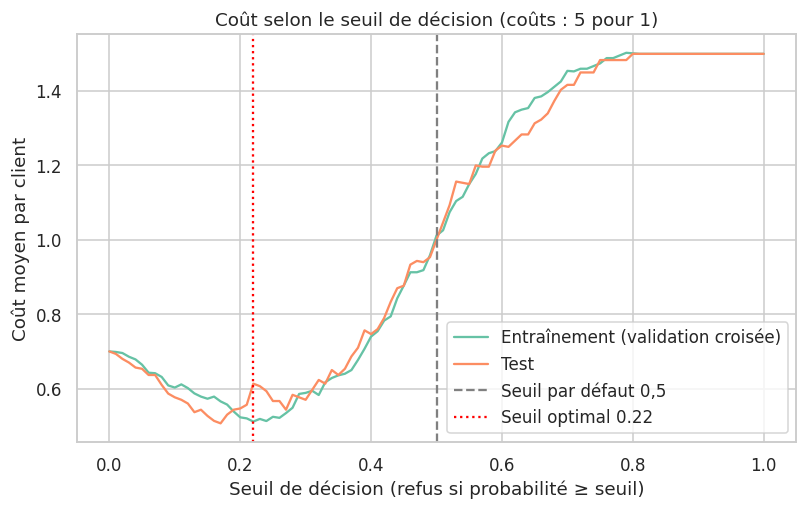

In [63]:
# Probabilités "hors pli" sur l'entraînement : elles servent à choisir le seuil sans toucher au test
p_oof = cross_val_predict(meilleur_pipe, X_train, y_train, cv=validation,
                          method="predict_proba")[:, 1]

seuils = np.linspace(0, 1, 101)
couts_train = np.array([cout_total(y_train, p_oof, s) for s in seuils])
couts_test = np.array([cout_total(y_test, p_test, s) for s in seuils])

seuil_opt = seuils[int(np.argmin(couts_train))]       # choisi sur l'entraînement uniquement
cout_05 = cout_total(y_test, p_test, 0.5)
cout_opt = cout_total(y_test, p_test, seuil_opt)

print(f"Seuil optimal (choisi sur l'entraînement) : {seuil_opt:.2f}")
print(f"Coût sur le test au seuil 0,5     : {cout_05}")
print(f"Coût sur le test au seuil optimal : {cout_opt}  (gain de {1 - cout_opt / cout_05:.0%})")

fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.plot(seuils, couts_train / len(y_train), label="Entraînement (validation croisée)")
ax.plot(seuils, couts_test / len(y_test), label="Test")
ax.axvline(0.5, color="grey", linestyle="--", label="Seuil par défaut 0,5")
ax.axvline(seuil_opt, color="red", linestyle=":", label=f"Seuil optimal {seuil_opt:.2f}")
ax.set_xlabel("Seuil de décision (refus si probabilité ≥ seuil)")
ax.set_ylabel("Coût moyen par client")
ax.set_title(f"Coût selon le seuil de décision (coûts : {C_FN} pour 1)")
ax.legend()
plt.tight_layout()
sauver("courbe_cout")
plt.show()

**Lecture.** Le seuil optimal, choisi sur l'entraînement, est **0,22**, assez proche du seuil théorique de 0,167. Sur le test, le coût total passe de **300** (seuil 0,5) à **184** (seuil 0,22), soit une baisse de **39 %**. Autrement dit, le coût moyen par client passe de 1,00 à 0,61. Abaisser le seuil rend le modèle plus sévère : il refuse plus de clients, mais laisse passer beaucoup moins de mauvais risques, ce qui compte davantage quand ces erreurs coûtent cinq fois plus.

L'écart entre le seuil optimal (0,22) et le seuil théorique (0,167) s'explique par le fait que les probabilités d'un modèle ne sont jamais parfaitement calibrées, et par la variabilité due à un échantillon de seulement 700 clients.

### 8.3 Matrices de confusion : seuil 0,5 contre seuil optimal

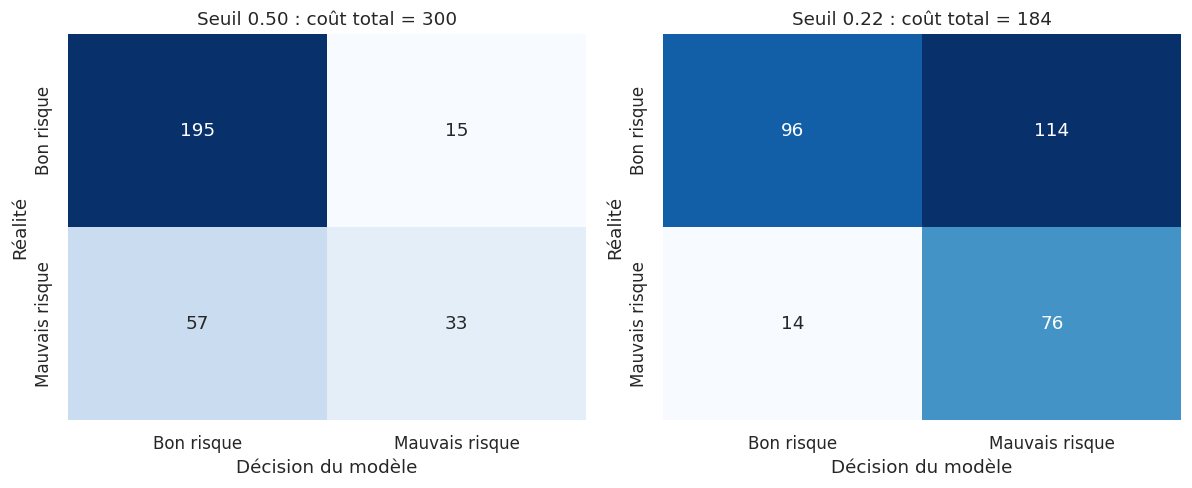

                precision    recall  f1-score   support

    Bon risque       0.87      0.46      0.60       210
Mauvais risque       0.40      0.84      0.54        90

      accuracy                           0.57       300
     macro avg       0.64      0.65      0.57       300
  weighted avg       0.73      0.57      0.58       300



In [64]:
# Matrices de confusion : seuil 0,5 contre seuil optimal (jeu de test)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, seuil in zip(axes, [0.5, seuil_opt]):
    pred = (p_test >= seuil).astype(int)
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=etiquettes,
                yticklabels=etiquettes, cbar=False, ax=ax)
    ax.set_title(f"Seuil {seuil:.2f} : coût total = {cout_total(y_test, p_test, seuil)}")
    ax.set_xlabel("Décision du modèle")
    ax.set_ylabel("Réalité")
plt.tight_layout()
sauver("matrices_confusion_seuils")
plt.show()

pred_opt = (p_test >= seuil_opt).astype(int)
print(classification_report(y_test, pred_opt, target_names=etiquettes))

**Lecture.** Au seuil optimal, le modèle détecte **84 %** des mauvais risques (contre 37 % au seuil de 0,5) : seulement 14 mauvais risques sont acceptés à tort, contre 57 auparavant. En contrepartie, il refuse **114 bons clients** (contre 15), et l'exactitude chute de 0,76 à 0,57. C'est le compromis voulu : on accepte de refuser beaucoup de bons clients (coût de 1 chacun) pour éviter les mauvais risques (coût de 5 chacun). Ce modèle est donc **moins bon en exactitude, mais meilleur en coût**, ce qui illustre pourquoi l'exactitude n'est pas la bonne métrique ici.

### 8.4 Analyse de sensibilité

Le ratio de 5 est une hypothèse. On refait le calcul avec des ratios de 2, 3, 5 et 10, en recalculant à chaque fois le seuil optimal sur l'entraînement. On compare aussi le modèle à deux stratégies sans modèle : **tout accepter** et **tout refuser**.

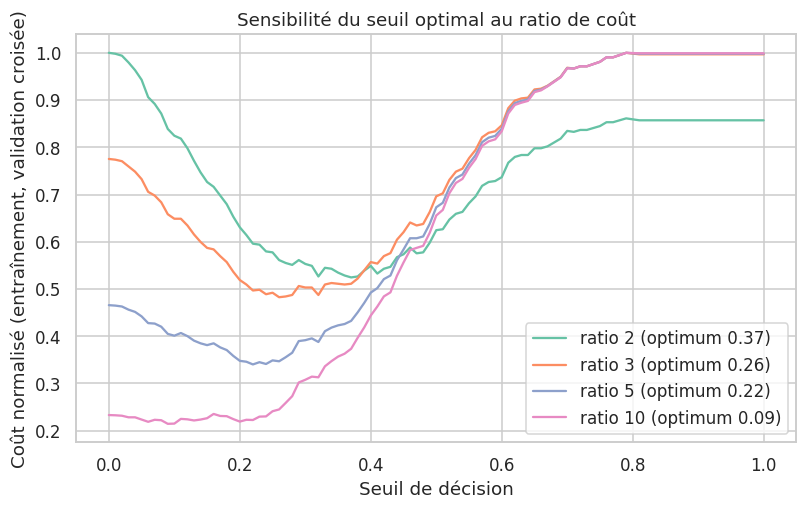

,Ratio,Seuil théorique,Seuil optimal,"Coût test à 0,5",Coût test au seuil optimal,Tout accepter,Tout refuser
0,2,0.333,0.37,129,110,180,210
1,3,0.250,0.26,186,138,270,210
2,5,0.167,0.22,300,184,450,210
3,10,0.091,0.09,585,181,900,210


In [65]:
# Analyse de sensibilité : le ratio de coût est une hypothèse, on le fait varier
ratios = [2, 3, 5, 10]
n_mauvais, n_bons = int(y_test.sum()), int((1 - y_test).sum())
lignes = []

fig, ax = plt.subplots(figsize=(7.5, 4.8))
for r in ratios:
    c_tr = np.array([cout_total(y_train, p_oof, s, c_fn=r, c_fp=1) for s in seuils])
    s_opt = seuils[int(np.argmin(c_tr))]
    c05 = cout_total(y_test, p_test, 0.5, c_fn=r, c_fp=1)
    copt = cout_total(y_test, p_test, s_opt, c_fn=r, c_fp=1)
    lignes.append({
        "Ratio": r, "Seuil théorique": round(1 / (1 + r), 3), "Seuil optimal": round(s_opt, 2),
        "Coût test à 0,5": c05, "Coût test au seuil optimal": copt,
        "Tout accepter": r * n_mauvais, "Tout refuser": n_bons,
    })
    ax.plot(seuils, c_tr / c_tr.max(), label=f"ratio {r} (optimum {s_opt:.2f})")
ax.set_xlabel("Seuil de décision")
ax.set_ylabel("Coût normalisé (entraînement, validation croisée)")
ax.set_title("Sensibilité du seuil optimal au ratio de coût")
ax.legend()
plt.tight_layout()
sauver("sensibilite")
plt.show()

df_sens = pd.DataFrame(lignes)
df_sens

**Lecture.** Plus le ratio augmente, plus le seuil optimal **baisse** (0,37 pour un ratio de 2, 0,26 pour 3, 0,22 pour 5 et 0,09 pour 10), et il reste proche du seuil théorique 1/(1 + ratio). Le modèle réduit toujours le coût par rapport au seuil de 0,5 : de 129 à 110 pour un ratio de 2, de 186 à 138 pour 3, de 300 à 184 pour 5 et de 585 à 181 pour 10. Le choix du ratio **influence donc fortement la décision**, et c'est l'hypothèse la plus fragile du projet.

La comparaison avec les stratégies sans modèle nuance le résultat. Le modèle bat toujours « tout accepter » et « tout refuser », mais pour un ratio de 10, son coût (181) est seulement 14 % sous celui de « tout refuser » (210) : quand une erreur sur un mauvais risque coûte très cher, un modèle d'AUC 0,78 n'apporte presque rien de plus que de refuser tous les prêts.

### 8.5 Un autre modèle serait-il meilleur ?

Sur le test, la régression logistique a un meilleur AUC que la forêt. On vérifie si elle donnerait aussi un meilleur coût, en choisissant son seuil de la même façon (sur l'entraînement). Ce n'est **pas** un moyen de choisir le modèle, car on regarde le test : c'est un test de robustesse.

In [66]:
# Un autre modèle donnerait-il un meilleur coût ? (seuil toujours choisi sur l'entraînement)
lignes = []
for nom in ["Régression logistique", "Forêt aléatoire"]:
    p_o = cross_val_predict(pipelines[nom], X_train, y_train, cv=validation,
                            method="predict_proba")[:, 1]
    s_o = seuils[int(np.argmin([cout_total(y_train, p_o, s) for s in seuils]))]
    lignes.append({
        "Modèle": nom, "AUC test": round(roc_auc_score(y_test, probas_test[nom]), 3),
        "Seuil optimal": round(s_o, 2),
        "Coût test à 0,5": cout_total(y_test, probas_test[nom], 0.5),
        "Coût test au seuil optimal": cout_total(y_test, probas_test[nom], s_o),
    })
df_comp = pd.DataFrame(lignes)
df_comp

,Modèle,AUC test,Seuil optimal,"Coût test à 0,5",Coût test au seuil optimal
0,Régression logistique,0.801,0.21,233,166
1,Forêt aléatoire,0.785,0.22,300,184


**Lecture.** La régression logistique obtient un coût de **166** au seuil optimal de 0,21 (contre 233 à 0,5), alors que la forêt obtient **184** (contre 300). La régression logistique fait donc un peu mieux sur ce test, de 18 unités sur un total proche de 180, soit environ 10 %. Cet écart est du même ordre que la variabilité d'un échantillon de 300 clients, et il ne suffit pas à affirmer que la logistique est meilleure. Les deux modèles conduisent à la **même conclusion** : un seuil autour de 0,2 réduit fortement le coût. Pour la suite, on conserve la **forêt aléatoire**, retenue selon la règle fixée à l'avance. On peut toutefois noter que la régression logistique, plus simple et plus interprétable, serait un choix tout aussi défendable en pratique.

## 9. Interprétation

### 9.1 Importance des variables

La forêt aléatoire permet de mesurer l'**importance** de chaque variable : la réduction moyenne de l'impureté de Gini qu'elle apporte dans les arbres. Les variables catégorielles étant transformées en plusieurs colonnes 0/1, on **additionne** les importances de toutes les colonnes issues de la même variable d'origine.

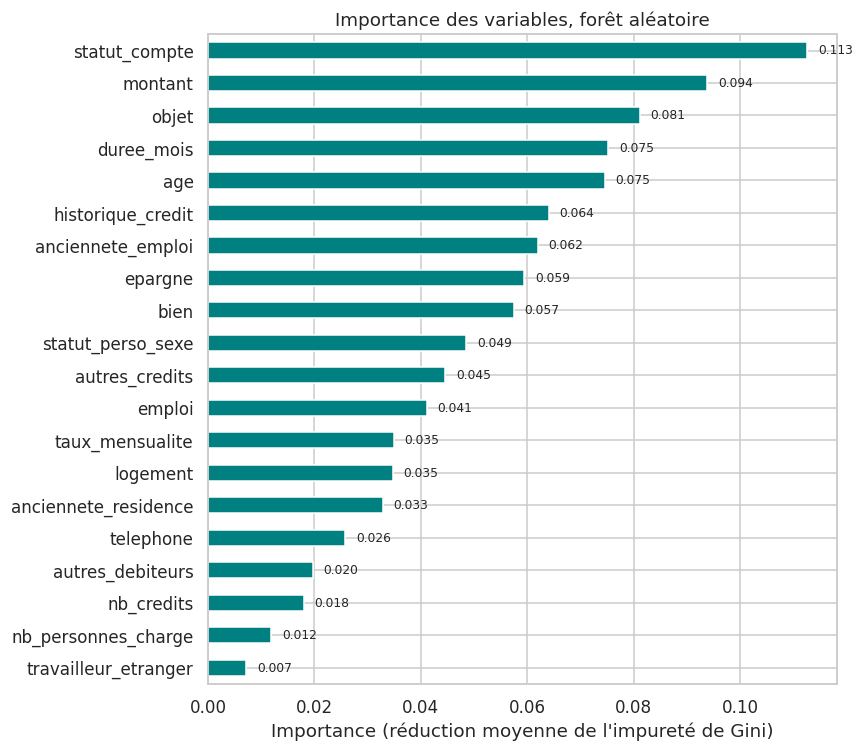

In [67]:
# Importance des variables pour la forêt aléatoire (regroupée par variable d'origine)
foret = Pipeline([("prep", preprocesseur),
                  ("modele", RandomForestClassifier(n_estimators=300, random_state=42))])
foret.fit(X_train, y_train)

def variable_origine(nom):
    nom = nom.replace("num__", "").replace("cat__", "")
    for v in variables_cat:
        if nom.startswith(v + "_"):
            return v
    return nom

noms = foret.named_steps["prep"].get_feature_names_out()
imp = pd.Series(foret.named_steps["modele"].feature_importances_, index=noms)
importances = imp.groupby(variable_origine).sum().sort_values()

fig, ax = plt.subplots(figsize=(8, 7))
importances.plot.barh(ax=ax, color="teal")
for i, val in enumerate(importances):
    ax.text(val + 0.002, i, f"{val:.3f}", va="center", fontsize=8)
ax.set_xlabel("Importance (réduction moyenne de l'impureté de Gini)")
ax.set_title("Importance des variables, forêt aléatoire")
plt.tight_layout()
sauver("importance_variables")
plt.show()

**Lecture.** La variable la plus importante est le **statut du compte courant** (0,113), suivie du **montant** (0,094), de l'**objet du crédit** (0,081), de la **durée** (0,075) et de l'**âge** (0,075), puis de l'historique de crédit (0,064). Cela rejoint l'exploration : le statut du compte faisait varier la part de mauvais risques de 12 % à 49 %, et la durée et le montant étaient les variables numériques les plus liées à la cible. À l'inverse, le statut de travailleur étranger (0,007), le nombre de personnes à charge (0,012) et le nombre de crédits (0,018) comptent très peu.

Trois précautions pour l'interprétation :
- l'importance de Gini **favorise les variables numériques continues** (montant, âge) et celles à beaucoup de modalités (objet, 10 modalités), donc leur place peut être un peu surestimée ;
- elle indique **combien** une variable sert au modèle, pas **dans quel sens** elle agit ;
- elle ne prouve **aucune causalité**.

Le jeu de données contient aussi une variable mêlant **statut personnel et sexe** (importance de 0,049), qui contribue donc aux décisions du modèle. Utiliser une telle variable pour accepter ou refuser un crédit pose des questions d'**équité** (et de légalité dans de nombreux pays) : ce travail ne les étudie pas, mais c'est une limite à mentionner.

### 9.2 Carte de la probabilité avec deux variables

Pour visualiser l'effet du seuil, on entraîne un modèle simple (régression logistique) sur **deux variables seulement** : la durée et le montant. La carte montre la probabilité de mauvais risque en chaque point, avec les deux seuils (0,5 et le seuil optimal).

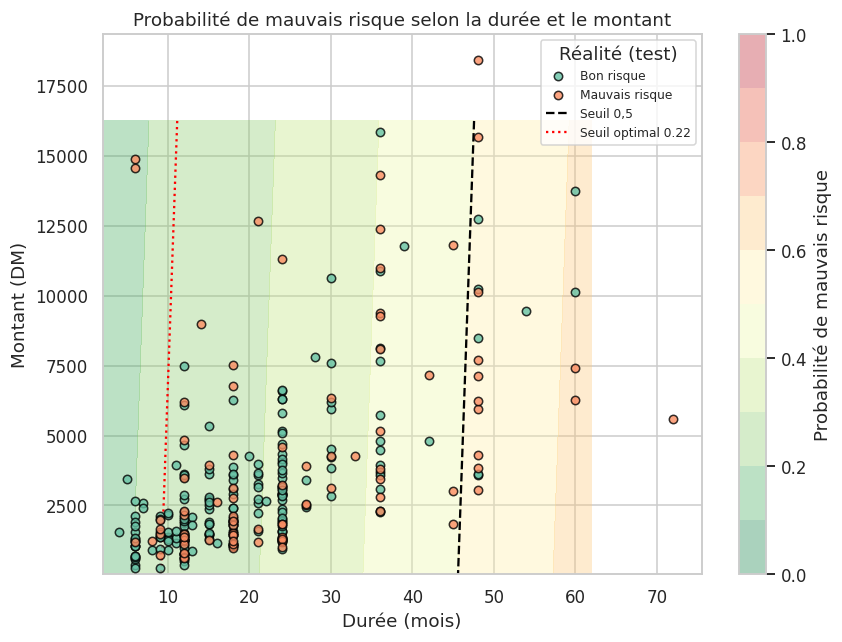

In [68]:
# Carte de la probabilité de mauvais risque avec deux variables : durée et montant
deux = ["duree_mois", "montant"]
modele_2d = Pipeline([("scaler", StandardScaler()), ("log", LogisticRegression())])
modele_2d.fit(X_train[deux], y_train)

x_min, x_max = X_train[deux[0]].min() - 2, X_train[deux[0]].max() + 2
y_min, y_max = X_train[deux[1]].min() - 300, X_train[deux[1]].max() + 300
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
grille = pd.DataFrame({deux[0]: xx.ravel(), deux[1]: yy.ravel()})
zz = modele_2d.predict_proba(grille)[:, 1].reshape(xx.shape)

fig, ax = plt.subplots(figsize=(8, 6))
carte = ax.contourf(xx, yy, zz, levels=np.linspace(0, 1, 11), cmap="RdYlGn_r", alpha=0.35)
plt.colorbar(carte, ax=ax, label="Probabilité de mauvais risque")
ax.contour(xx, yy, zz, levels=[0.5], colors="black", linestyles="--")
ax.contour(xx, yy, zz, levels=[seuil_opt], colors="red", linestyles=":")
for valeur, etiquette in [(0, "Bon risque"), (1, "Mauvais risque")]:
    masque = y_test == valeur
    ax.scatter(X_test.loc[masque, deux[0]], X_test.loc[masque, deux[1]],
               label=etiquette, s=30, edgecolor="k", alpha=0.8, zorder=3)
ax.plot([], [], "k--", label="Seuil 0,5")
ax.plot([], [], "r:", label=f"Seuil optimal {seuil_opt:.2f}")
ax.set_xlabel("Durée (mois)")
ax.set_ylabel("Montant (DM)")
ax.set_title("Probabilité de mauvais risque selon la durée et le montant")
ax.legend(title="Réalité (test)", loc="upper right", fontsize=8)
plt.tight_layout()
sauver("carte_probabilite")
plt.show()

**Lecture.** Les zones de probabilité sont presque **verticales** : avec ces deux variables, la probabilité de mauvais risque dépend surtout de la **durée**, et le montant ajoute peu. Le seuil de 0,5 (ligne en tirets) se situe vers 45 mois, c'est-à-dire qu'il ne refuserait que des crédits très longs. Le seuil de 0,22 (ligne en pointillés rouges) se situe vers 10 mois : il refuserait presque tous les crédits de plus de 10 mois. On retrouve visuellement l'effet de la partie coûts : **abaisser le seuil déplace la frontière vers la gauche** et rend le modèle beaucoup plus sévère.

Les deux classes restent très **mélangées** sur toute la carte : deux variables ne suffisent pas à séparer les clients, ce qui justifie d'utiliser les 20 variables. Attention : le seuil de 0,22 a été optimisé pour la forêt aléatoire, et non pour ce petit modèle à deux variables. Cette carte est donc **illustrative**, elle ne donne pas la frontière de décision du modèle retenu.

## 10. Prédire un nouveau client

On construit un client fictif et on calcule sa probabilité d'être un mauvais risque avec le modèle retenu. Toutes les variables doivent être renseignées, avec des codes de catégories existants.

In [69]:
# Nouveau client fictif, avec sa probabilité d'être un mauvais risque
nouveau = pd.DataFrame([{
    "statut_compte": "A11", "duree_mois": 24, "historique_credit": "A32", "objet": "A43",
    "montant": 3000, "epargne": "A61", "anciennete_emploi": "A73", "taux_mensualite": 3,
    "statut_perso_sexe": "A93", "autres_debiteurs": "A101", "anciennete_residence": 2,
    "bien": "A122", "age": 35, "autres_credits": "A143", "logement": "A152", "nb_credits": 1,
    "emploi": "A173", "nb_personnes_charge": 1, "telephone": "A191", "travailleur_etranger": "A201",
}])

p_nouveau = meilleur_pipe.predict_proba(nouveau)[0, 1]
print(f"Probabilité de mauvais risque : {p_nouveau:.2f}")
print(f"Décision au seuil 0,5                  : {'Refuser' if p_nouveau >= 0.5 else 'Accepter'}")
print(f"Décision au seuil optimal ({seuil_opt:.2f})      : {'Refuser' if p_nouveau >= seuil_opt else 'Accepter'}")

Probabilité de mauvais risque : 0.70
Décision au seuil 0,5                  : Refuser
Décision au seuil optimal (0.22)      : Refuser


**Lecture.** Ce client fictif demande 3 000 DM sur 24 mois, avec un compte courant à solde négatif (A11), une épargne faible (A61) et 35 ans. Le modèle lui attribue une probabilité d'environ **0,70** d'être un mauvais risque : il serait **refusé** aux deux seuils (0,5 et 0,22). Les clients à probabilité intermédiaire, entre 0,22 et 0,5, sont ceux dont la décision change selon le seuil : c'est précisément là que la matrice de coûts modifie la décision. Cette prédiction est fictive et sert à illustrer le fonctionnement du modèle, pas à prendre une décision réelle.

## 11. Synthèse et limites

### Ce qu'il faut retenir

**Données.** Le jeu *German Credit* contient 1 000 clients, 20 variables (7 numériques, 13 catégorielles) et une cible déséquilibrée : 30 % de mauvais risques. Il n'y a ni valeur manquante ni doublon.

**Modèles.** Tous les modèles font mieux que la référence (AUC = 0,5). En validation croisée, la **forêt aléatoire** (0,785) devance la régression logistique (0,764), les K voisins (0,695) et l'arbre de décision (0,668), mais l'écart entre les deux premières est dans la marge d'erreur. La forêt a été retenue par une règle fixée à l'avance, sans regarder le jeu de test. Sur le test, son AUC est de 0,785 (0,801 pour la régression logistique).

**Surapprentissage.** L'arbre de décision mémorise les données dès qu'il devient profond (AUC d'entraînement de 1,00, de validation d'environ 0,62 pour une profondeur de 15). La forêt atteint aussi 1,00 à l'entraînement, et sa courbe d'apprentissage montre qu'un échantillon plus grand aiderait.

**Seuil de décision.** Au seuil par défaut de 0,5, la forêt ne détecte que 37 % des mauvais risques et laisse passer 57 d'entre eux sur 90. Avec un coût de 5 pour un mauvais risque accepté et de 1 pour un bon client refusé, le seuil optimal, choisi sur l'entraînement, est **0,22** : il fait passer le coût du test de **300 à 184** (-39 %) et la détection des mauvais risques à 84 %, au prix de 114 bons clients refusés (contre 15).

**Sensibilité.** Plus le ratio de coût augmente, plus le seuil optimal baisse (0,37 pour 2, 0,26 pour 3, 0,22 pour 5, 0,09 pour 10). Le modèle réduit toujours le coût, mais pour un ratio de 10 il ne fait que 14 % mieux que « tout refuser ». La régression logistique donne un résultat comparable (coût de 166 contre 184 pour la forêt).

**Variables importantes.** Le statut du compte courant, le montant, l'objet du crédit, la durée et l'âge pèsent le plus dans la forêt.

### Limites

- **Les coûts sont des hypothèses**, pas des données réelles de la banque. Toute la partie sur le seuil dépend du ratio choisi.
- **Données petites et anciennes** : 1 000 dossiers, montants en marks allemands. Le test ne compte que 300 clients, donc les coûts mesurés sont très variables, et la courbe d'apprentissage n'est pas stabilisée.
- **Un seul découpage** entraînement/test : les résultats peuvent changer avec une autre graine aléatoire.
- **Pas de réglage fin** des hyperparamètres (nombre d'arbres, profondeur...), pour garder une comparaison simple.
- **Probabilités non calibrées** : le seuil optimal (0,22) s'écarte du seuil théorique (0,167), et un modèle différent donnerait des seuils différents.
- **Équité** : le jeu contient des variables comme le statut personnel et sexe ou le statut de travailleur étranger. Les utiliser pour refuser un crédit soulève des questions éthiques et légales, que ce travail n'étudie pas.
- **Biais de sélection probable** : les clients du jeu de données sont, a priori, des personnes à qui un crédit a été accordé. On ne sait rien de ceux qui ont été refusés, donc le modèle ne reflète pas forcément toute la population qui fait une demande.
- **Corrélation et causalité** : les modèles apprennent des associations, pas des causes.

### Pour aller plus loin

Régler les hyperparamètres, tester d'autres modèles (gradient boosting), **calibrer** les probabilités, utiliser une validation croisée répétée pour estimer la variabilité des coûts, et obtenir des coûts réalistes auprès d'un professionnel du crédit.

## Export des figures et tableaux pour le rapport LaTeX

In [70]:
# Export des tableaux en LaTeX directement dans le Drive (les figures y sont déjà)
tableau.round(3).to_latex(f"{DOSSIER_FIG}/tableau_validation_croisee.tex", index=False)
df_test.round(3).to_latex(f"{DOSSIER_FIG}/tableau_auc_test.tex", index=False)
df_sens.to_latex(f"{DOSSIER_FIG}/tableau_sensibilite.tex", index=False)
df_comp.to_latex(f"{DOSSIER_FIG}/tableau_comparaison_cout.tex", index=False)

print("Contenu de", DOSSIER_FIG)
for f in sorted(os.listdir(DOSSIER_FIG)):
    print(" -", f)

Contenu de /content/drive/MyDrive/risque_credit_allemagne/figures
 - boites_moustaches.pdf
 - carte_probabilite.pdf
 - comparaison_modeles.pdf
 - correlations.pdf
 - courbe_apprentissage.pdf
 - courbe_cout.pdf
 - courbes_roc.pdf
 - distributions.pdf
 - importance_variables.pdf
 - matrice_confusion_05.pdf
 - matrices_confusion_seuils.pdf
 - nuage_montant_duree.pdf
 - part_mauvais_risques.pdf
 - profondeur_arbre.pdf
 - repartition_cible.pdf
 - sensibilite.pdf
 - tableau_auc_test.tex
 - tableau_comparaison_cout.tex
 - tableau_sensibilite.tex
 - tableau_validation_croisee.tex
